# Phys 434 Lab 3 - Asking a Statistical Question

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas as pd
plt.rcParams["figure.figsize"] = (20,15)

### Problem 1
In our first example we are looking at the temperature reading (meta-data) associated with an experiment. For the experiment to work reliably, the temperature should be at around 12 Kelvin, and if we look at the data it is mostly consistent with 12 Kelvin to within the 0.4 degree precision of the thermometry and the thermal control system (standard deviation). However, there are times when the thermal control system misbehaved and the temperature was not near 12 K, and in addition there are various glitches in the thermometry that give anomalously high and low readings (the reading does not match the real temperature). We definitely want to identify and throw out all the data when the thermal control system was not working (and the temperature was truly off from nominal). While it is possible to have an error in the thermometry such that the true temperature was fine, and we just had a wonky reading, in an abundance of caution we want to throw those values out too.

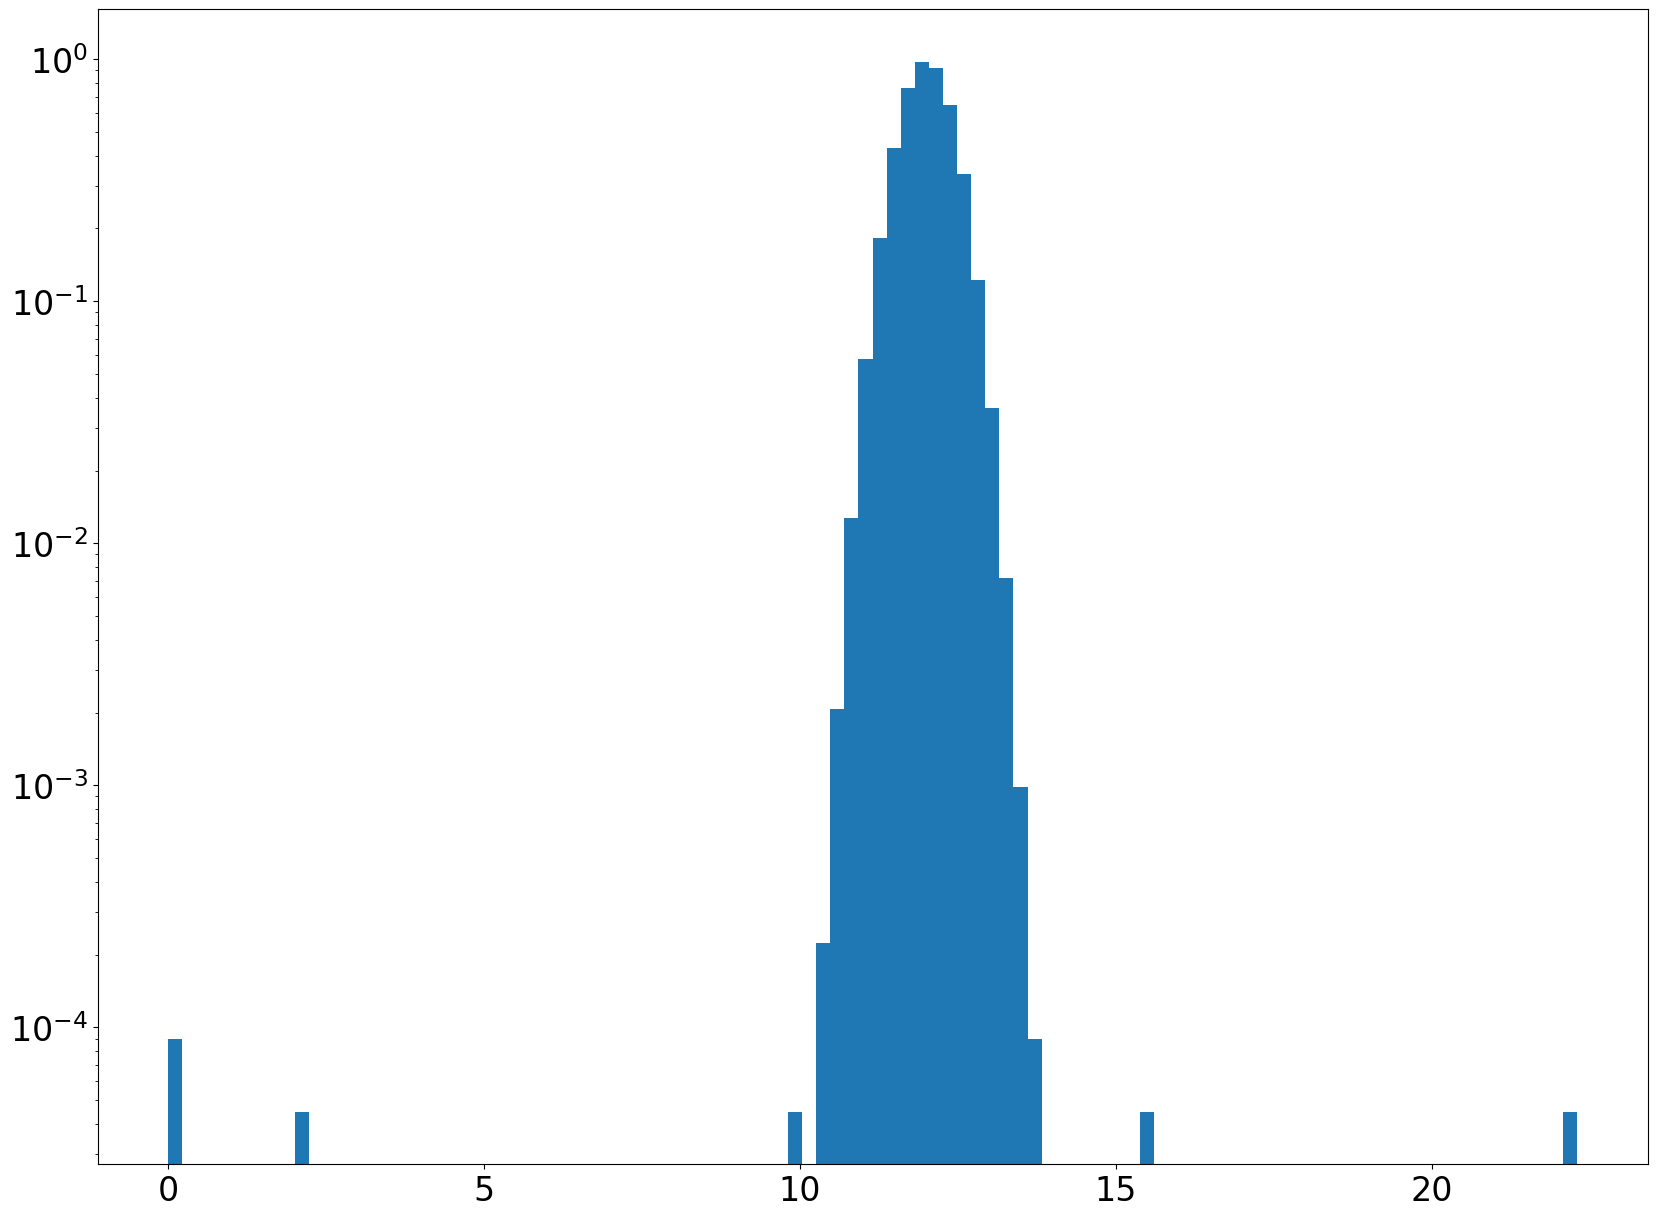

In [2]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

#### A) So our goal is to identify bad data and throw it out.

1. Start by exploring the data you have created with appropriate plots
2. State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.
3. Restate your question in math. Be very clear.
4. Apply your statistical test and construct a truth table.

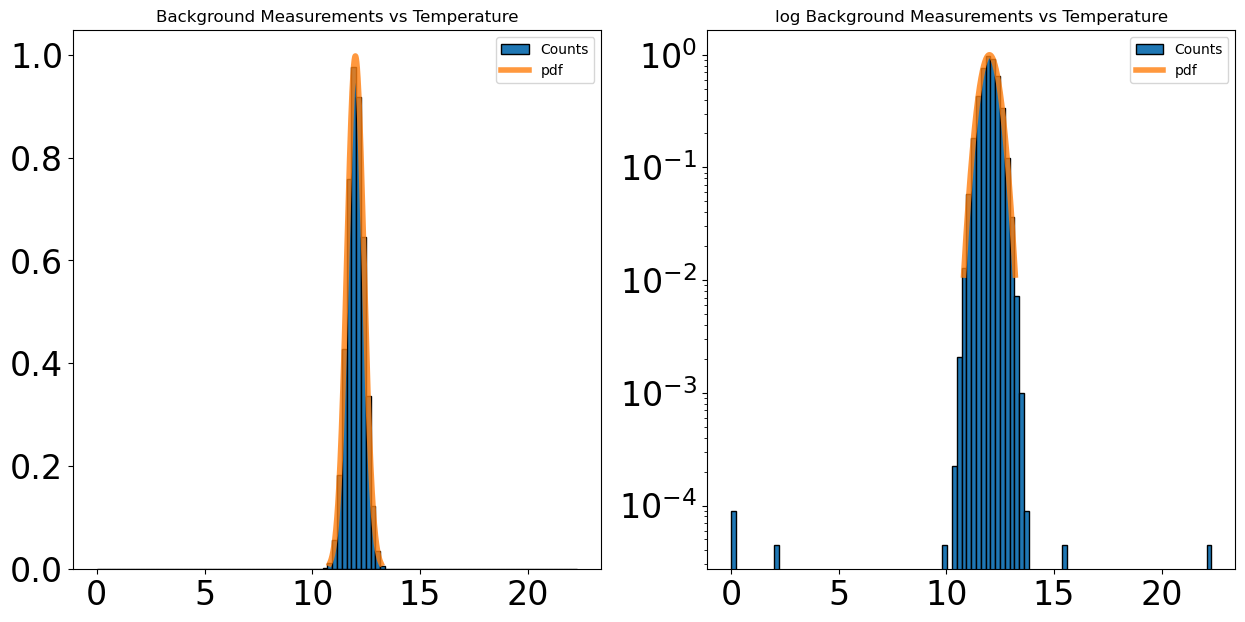

In [13]:
x = np.linspace(10.8,13.2, 1000)
pdf = stats.norm.pdf(x, loc = 12., scale = 0.4)

fig, ax = plt.subplot_mosaic(
    """
    AB
    """,
    figsize = (15,7)
)
ax['A'].tick_params(labelsize = 24)
ax['A'].hist(d,100, density=True, edgecolor = 'black', label = 'Counts')
ax['A'].plot(x, pdf, linewidth = 4, alpha = 0.8, label = 'pdf')
ax['A'].set_title('Background Measurements vs Temperature')
ax['A'].legend(loc = 0)

ax['B'].tick_params(labelsize = 24)
ax['B'].hist(d,100, density=True, edgecolor = 'black', label = 'Counts')
ax['B'].plot(x, pdf, linewidth = 4, alpha = 0.8, label = 'pdf')
ax['B'].set_yscale('log')
ax['B'].set_title('log Background Measurements vs Temperature')
ax['B'].legend(loc = 0)

**Statistical Question**

What is the likelihood that a signal free Gaussian background produces datapoints greater than 3 sigma from the mean?

This question asks how likely a datapoint that is more than 1.2K from the 12K mean is to be a real part of the background. 3 sigma captures 99.7% of the ideal readings, so it should be safe for any datapoints outside of it to be thrown out. 

**Mathematical Representation**

$$\mathcal P_{T\leq 10.8, \; 13.2 \leq T} = 1 - \frac{1}{\sqrt{2\pi} (0.4)^2} \int_{10.8}^{13.2} e^{\frac{(T-12)^2}{2(0.4)^2}} \mathrm dT$$

In [4]:
# Probability Sum
p_g3 = stats.norm.sf(13.2, scale = 0.4, loc = 12)
p_l3 = stats.norm.cdf(10.8, scale = 0.4, loc = 12)

p_tot = p_g3 + p_l3

print(f'The percent of true data points falling outside the range 10.8 to 13.2 is {p_tot*100:.2f}%')

The percent of true data points falling outside the range 10.8 to 13.2 is 0.27%


In [5]:
d_filt = d[(10.8<d) & (d<13.2)]

In [6]:
good_test = len(d_filt)-1
bad_test =100000 - good_test

T_data = {" ":['Test Good', 'Test Bad'], "True T":[good_test, bad_test], "False T":[1,7]}
T = pd.DataFrame(data = T_data)
T.style.hide(axis = 'index')

,True T,False T
Test Good,99741,1
Test Bad,259,7


#### B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

The number of omissions is a predictable quantity because it is chosen based on the sigma threshold you choose for good data. For our sample size of 100k datapoints, the number of data points being thrownout is on average $100000(1-\mathcal P_{-3\sigma \leq T \leq 3\sigma})$ which can be calculated based purely on the expected background.

#### C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

Yes, for my sigma threshold of $3\sigma$ 1 bad datapoint made it into the dataset, it is not neccessarily avoidable because sometimes the bad data falls within your acceptable sigma range, however number of mistakes tends to decreases with the size of your acceptable sigma range at the cost of good data omission.

### Problem 2
In this example we will be looking for asteroids. If we look at the alignment of stars on subsequent images, they don't perfectly align due to atmospheric and instrumental effects (even ignoring proper motion). The resulting distribution is two dimensional, and for this lab let's assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if I histogram how far all the (stationary) stars appear to have moved I get something like:

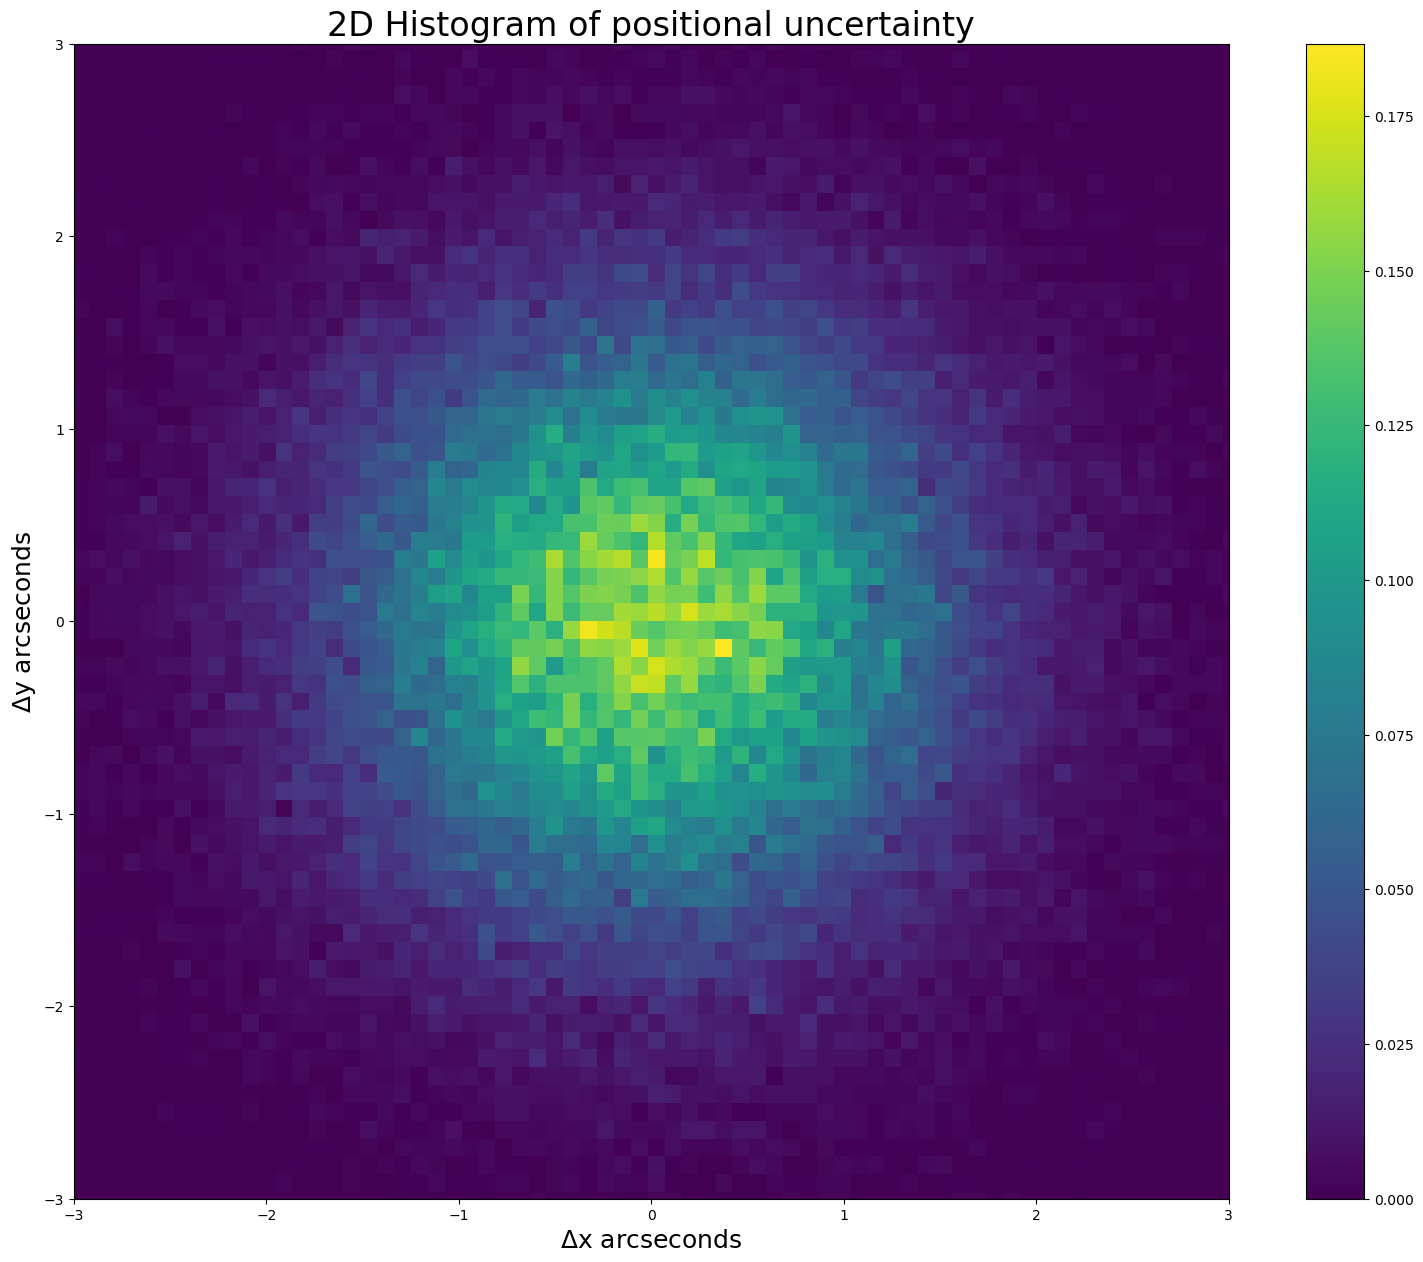

In [7]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta$y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds?

**What is the question in words?**
If an asteroid can only be identified by having a movement greater than 5 sigma of the positional uncertainty, what distance in arcseconds must it have moved?

**What is the question in math? [Hint: Come up with an analytic description of your pdf(). The Blue Book may be helpful here.]**

The distribution of the amplitude of a 2D Gaussian is a Rayleigh distribution of the form:
$${f(x;\sigma )={\frac {x}{\sigma ^{2}}}e^{-x^{2}/(2\sigma ^{2})},\quad x\geq 0}$$

Which for this problem has $\sigma^2 = 1$


To compute the value of 5 sigma for the rayleigh distribution:
$$\mathcal P_{x\leq 5\sigma} = \int_{5}^{\infty} \frac{1}{\sqrt{2\pi}} e^{\frac{-x^2}{2}} \mathrm dx $$

$$\mathcal P_{x\leq 5\sigma} = \int_{n}^{\infty} {\frac {x}{\sigma ^{2}}}e^{-x^{2}/(2\sigma ^{2})} \mathrm dx $$

where n is the motion value associated with $5\sigma$.

**What distance in arcseconds represents a 5 sigma detection of motion?**

In [8]:
# Get the probability of a 5 sigma observation from the standard normal dist
prob_5s = stats.norm.sf(5)

# Now compute the isf of the rayleigh distribution with RMS 1 arcsecond
dist_5s = stats.rayleigh.isf(prob_5s)
print(f'The distance in arseconds for a 5 sigma detection of motion is {dist_5s:.2f}"')

The distance in arseconds for a 5 sigma detection of motion is 5.49"


# Problem 3
As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

1.**What is the question in words?**

While observing the moon for 8 hours a day over a period of 15 days, what is the significance of the deviation of the observed cosmic rays from those expected by the background if the background is given by a rate of 1 cosmic ray per minute on average?
    
2. **Translate the question to math, describing both the expected background pdf() and the integral you need to do.**

Cosmic rays are discrete and cannot be "negative" so the background is best represented by a Poisson distribution:

$${f(k;\lambda )={\frac {\lambda ^{k}e^{-\lambda }}{k!}}}$$

Where lambda is the expected number of events per observation. If you now sum repeated observations, the distribution becomes:

$$ f(k;\lambda = rt )=\frac {(rt)^{k}e^{-rt}}{k!}$$

Where rt is the rate of background over total observation time, for this scenario 1 cosmic ray/min times 7200 minutes.

The probability of 6800 occurences over the observation time is given by:

$$\mathcal P_{x\leq 6800}=\sum_n^{6800} \frac {(7200)^{n}e^{-7200}}{n!}$$

and the sigma(n) can be found as:

$$\mathcal P_{x\leq 6800} = \int_{-\infty}^{n} \frac{1}{\sqrt{2\pi}} e^{\frac{-x^2}{2}} \mathrm dx $$

4. **Convert to sigma.**

In [9]:
moon_prob = stats.poisson.cdf(6800, mu = 7200)
moon_sigma = stats.norm.ppf(moon_prob)
print(f'The sigma of the cosmic rays observed through the moon is {moon_sigma:.2f} below the mean.')

The sigma of the cosmic rays observed through the moon is -4.75 below the mean.
